# Inference on Finetuned NEMO Models

- Creator: Arpit Merchant (am84@sanger.ac.uk)
- Date of Creation: 21.11.2025
- Date of Last Modification: 26.11.2025 (by Arpit Merchant; am84@sanger.ac.uk)

In [1]:
%load_ext autoreload
%autoreload 2

In [82]:
import re
import os
import yaml
import tempfile
import shutil
import pickle
from tqdm import tqdm
from collections import Counter
from pathlib import Path
from typing import Dict, List, Optional, Tuple, Union

import numpy as np
import scanpy as sc
import pandas as pd
import anndata as ad
from sklearn.metrics import accuracy_score, f1_score

import seaborn as sns
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from datasets import Dataset, load_from_disk

In [62]:
from app.helper import init_model, apply_peft, load_checkpoint
from nichejepa.models.modules import ClassificationModel
from nichejepa.datasets.cell_datasets import init_cell_dataset
from nichejepa.datasets.dataloaders import init_dataloader_and_sampler
from nichejepa.masks.block_masking import BlockMaskCollator
from nichejepa.utils.embedding import create_binary_selection_mask

In [4]:
NUM_CORES = int(os.environ.get("LSB_DJOB_NUMPROC",1))
print(NUM_CORES)

6


In [44]:
# Set device
if not torch.cuda.is_available():
    device = torch.device('cpu')
else:
    device = torch.device('cuda:0')
    torch.cuda.set_device(device)

# Helper Functions

## Loading Checkpoints

In [19]:
def load_checkpoints_from_directory(
    checkpoint_dir: str | Path,
    pattern: str = r'ft_\d+\.pt',
    sort_by_epoch: bool = True
) -> Dict[int, Dict]:
    """
    Load all checkpoint files from a given directory.
    
    Parameters
    ----------
    checkpoint_dir : str | Path
        Path to the directory containing checkpoint files
    pattern : str
        Regex pattern to match checkpoint filenames (default: 'ft_\\d+\\.pt')
    sort_by_epoch : bool
        If True, sort checkpoints by epoch number (default: True)
    
    Returns
    -------
    Dict[int, Dict]
        Dictionary mapping epoch numbers to loaded checkpoint dictionaries.
        Each checkpoint dict contains:
        - 'model': model state_dict
        - 'opt': optimizer state_dict
        - 'epoch': epoch number
        - 'zero_epoch_tracking': bool
        - 'loss': epoch loss
        - 'accuracy': epoch accuracy
        - 'batch_size': batch size
        - 'world_size': world size
        - 'lr': learning rate
        - 'model_name': model name
    """
    checkpoint_dir = Path(checkpoint_dir)
    
    if not checkpoint_dir.exists():
        raise FileNotFoundError(f"Directory not found: {checkpoint_dir}")
    
    if not checkpoint_dir.is_dir():
        raise ValueError(f"Path is not a directory: {checkpoint_dir}")
    
    # Find all matching checkpoint files
    checkpoint_files = []
    for file_path in checkpoint_dir.iterdir():
        if file_path.is_file() and re.match(pattern, file_path.name):
            checkpoint_files.append(file_path)
    
    if not checkpoint_files:
        raise ValueError(f"No checkpoint files found matching pattern '{pattern}' in {checkpoint_dir}")
    
    # Load all checkpoints
    checkpoints = {}
    for file_path in checkpoint_files:
        # Extract epoch number from filename (e.g., 'ft_3.pt' -> 3)
        match = re.search(r'ft_(\d+)\.pt', file_path.name)
        if match:
            epoch = int(match.group(1))
            checkpoint = torch.load(file_path, map_location='cpu')
            checkpoints[epoch] = checkpoint
        else:
            # If pattern doesn't match, use filename as key
            checkpoint = torch.load(file_path, map_location='cpu')
            checkpoints[file_path.name] = checkpoint
    
    # Sort by epoch if requested
    if sort_by_epoch and all(isinstance(k, int) for k in checkpoints.keys()):
        checkpoints = dict(sorted(checkpoints.items()))

    print(f"Loaded {len(checkpoints)} checkpoints")
    for epoch, checkpoint in checkpoints.items():
        print(f"\nEpoch {epoch}:")
        print(f"  Loss: {checkpoint.get('loss', 'N/A'):.4f}")
        print(f"  Accuracy: {checkpoint.get('accuracy', 'N/A'):.4f}")
        print(f"  Model Name: {checkpoint.get('model_name', 'N/A')}")

    return checkpoints


def get_best_checkpoint(
    checkpoints: Dict[int, Dict],
) -> Dict:
    """
    Find the checkpoint with the lowest loss from already-loaded checkpoints.
    
    Parameters
    ----------
    checkpoints : Dict[int, Dict]
        Dictionary of checkpoints loaded using load_checkpoints_from_directory,
        where keys are epoch numbers and values are checkpoint dictionaries
    
    Returns
    -------
        - full checkpoint
    """
    if not checkpoints:
        raise ValueError("Checkpoints dictionary is empty")
    
    # Find checkpoint with lowest loss
    best_epoch = None
    best_loss = float('inf')
    best_checkpoint = None
    
    for epoch, checkpoint in checkpoints.items():
        loss = checkpoint.get('loss')
        
        if loss is None:
            print(f"Warning: Checkpoint at epoch {epoch} has no 'loss' field, skipping...")
            continue
        
        if loss < best_loss:
            best_loss = loss
            best_epoch = epoch
            best_checkpoint = checkpoint
    
    if best_checkpoint is None:
        raise ValueError("No checkpoint with valid loss found")
    
    # Print epoch number
    print(f"Best checkpoint: Epoch {best_epoch} with loss {best_loss:.4f}")
    
    return best_checkpoint

## Plotting

In [77]:
def plot_training_curves(
    list_of_model_checkpoints: List[Dict],
    model_names: List[str] = None,
    figsize: tuple = (12, 5),
    save_path: str = None
):
    """
    Plot training loss and accuracy curves from multiple checkpoint directories.
    
    Parameters
    ----------
    list_of_model_checkpoints : List[Dict]
        List of pre-loaded checkpoint dictionaries for one or more models.
    model_names : List[str], optional
        Names of models (for legend). If None, uses model_name from checkpoints.
    figsize : tuple
        Figure size (width, height). Default: (12, 5)
    save_path : str, optional
        Path to save the figure. If None, figure is displayed.
    """
    all_data = []
    for idx, model_checkpoints in enumerate(list_of_model_checkpoints):
        # Extract data from checkpoints
        for epoch, checkpoint in model_checkpoints.items():
            if model_names:
                model_name = model_names[idx]
            else:            
                model_name = checkpoint.get('model_name', f'Model_{idx}')
            loss = checkpoint.get('loss')
            accuracy = checkpoint.get('accuracy')
            
            if loss is not None and accuracy is not None:
                all_data.append({
                    'epoch': epoch,
                    'loss': loss,
                    'accuracy': accuracy,
                    'model_name': model_name,
                    'checkpoint_set': idx
                })

    if not all_data:
        raise ValueError("No valid checkpoint data found")
        
    # Convert to DataFrame
    df = pd.DataFrame(all_data)
    
    # Create figure with two subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize)
    
    # Plot 1: Loss
    sns.lineplot(
        data=df,
        x='epoch',
        y='loss',
        hue='model_name',
        marker='o',
        ax=ax1
    )
    ax1.set_xlabel('Epoch', fontsize=12)
    ax1.set_ylabel('Train Loss', fontsize=12)
    ax1.set_title('Training Loss', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.legend(title='Model', fontsize=10)
    
    # Plot 2: Accuracy
    sns.lineplot(
        data=df,
        x='epoch',
        y='accuracy',
        hue='model_name',
        marker='o',
        ax=ax2
    )
    ax2.set_xlabel('Epoch', fontsize=12)
    ax2.set_ylabel('Train Accuracy', fontsize=12)
    ax2.set_title('Training Accuracy', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.legend(title='Model', fontsize=10)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Figure saved to {save_path}")
    else:
        plt.show()

In [78]:
def add_predicted_labels_to_adata(
    df: pd.DataFrame,
    adata: ad.AnnData,
    label_prefix: str = "niche19",
    predicted_label_col: str = "predicted_label",
    cell_id_col: str = "cell_id",
    output_col_name: str = None
) -> None:
    """
    Add predicted labels from a dataframe to an AnnData object.
    
    Parameters
    ----------
    df : pd.DataFrame
        DataFrame containing cell_id and predicted_label columns.
        predicted_label should be integers (0 to num_classes-1).
    adata : AnnData
        AnnData object containing test data with uns[f'{label_prefix}_idx2label'] mapping.
    label_prefix : str, default="niche19"
        Prefix for the label mapping in adata.uns. The function will look for
        adata.uns[f'{label_prefix}_idx2label'] which should map string keys like '0', '1', etc.
        to label names.
    predicted_label_col : str, default="predicted_label"
        Name of the column in df containing the predicted label indices.
    cell_id_col : str, default="cell_id"
        Name of the column in df containing cell IDs.
    output_col_name : str, optional
        Name of the output column in adata.obs. If None, defaults to f'zsl_{label_prefix}'.
    
    Returns
    -------
    None
        Modifies adata.obs in place by adding the predicted label column.
    """
    # Set default output column name
    if output_col_name is None:
        output_col_name = f'zsl_{label_prefix}'
    
    # Get the label mapping dictionary
    idx2label_key = f'{label_prefix}_idx2label'
    if idx2label_key not in adata.uns:
        raise KeyError(f"'{idx2label_key}' not found in adata.uns. Available keys: {list(adata.uns.keys())}")
    
    idx2label = adata.uns[idx2label_key]
    
    # Convert predicted_label indices to string labels using the mapping
    # Convert integer predicted_label to string key first, then map
    df = df.copy()  # Avoid modifying original dataframe
    df[output_col_name] = df[predicted_label_col].astype(str).map(idx2label)
    
    # Create a lookup dictionary from df indexed by cell_id
    label_lookup = df.set_index(cell_id_col)[output_col_name]
    
    # Match with adata.obs['cell_id'] and create the new column
    adata.obs[output_col_name] = adata.obs['cell_id'].map(label_lookup)
    
    # Log summary
    missing_count = adata.obs[output_col_name].isna().sum()
    total_count = len(adata.obs)
    print(f"Added '{output_col_name}' to adata.obs: {total_count - missing_count}/{total_count} cells matched")
    if missing_count > 0:
        print(f"Found {missing_count} cell_ids in adata.obs that are not in df")

In [79]:
def plot_spatial_comparison(
    adata,
    column_names: List[str],
    spatial_key: str = "spatial",
    dataset_id_col: str = "dataset_id",
    batch_col: str = "batch",
    figsize: Optional[tuple] = None,
    spot_size: Optional[float] = None,
    title_prefix: str = "",
    save_path: Optional[str] = None,
    dpi: int = 300,
    **kwargs
):
    """
    Create spatial plots for multiple columns with a unified color legend.
    Each row corresponds to a unique combination of dataset_id + batch.
    Each column corresponds to a column name in column_names.
    
    Parameters
    ----------
    adata : AnnData
        AnnData object containing spatial coordinates and annotation columns.
    column_names : List[str]
        List of column names in adata.obs to plot (e.g., ['niche19', 'zsl_niche19']).
    spatial_key : str, default="spatial"
        Key in adata.obsm containing spatial coordinates (shape: n_cells x 2).
        If not found in obsm, will look for 'x' and 'y' columns in adata.obs.
    dataset_id_col : str, default="dataset_id"
        Column name in adata.obs containing dataset IDs.
    batch_col : str, default="batch"
        Column name in adata.obs containing batch information.
    figsize : tuple, optional
        Figure size (width, height). If None, auto-calculated based on grid size.
    spot_size : float, optional
        Size of spots in the plot. If None, uses default size.
    title_prefix : str, default=""
        Prefix to add to each subplot title.
    save_path : str, optional
        Path to save the figure. If None, figure is not saved.
    dpi : int, default=300
        Resolution for saved figure.
    **kwargs
        Additional arguments passed to scatter plot.
    
    Returns
    -------
    fig, axes
        Matplotlib figure and axes objects.
    """
    # Validate columns exist
    missing_cols = [col for col in column_names if col not in adata.obs.columns]
    if missing_cols:
        raise ValueError(f"Columns not found in adata.obs: {missing_cols}")
    
    # Validate dataset_id and batch columns exist
    if dataset_id_col not in adata.obs.columns:
        raise ValueError(f"Column '{dataset_id_col}' not found in adata.obs.columns")
    if batch_col not in adata.obs.columns:
        raise ValueError(f"Column '{batch_col}' not found in adata.obs.columns")
    
    # Get spatial coordinates
    if spatial_key in adata.obsm:
        coords = adata.obsm[spatial_key]
    elif 'x' in adata.obs.columns and 'y' in adata.obs.columns:
        coords = adata.obs[['x', 'y']].values
    else:
        raise ValueError(
            f"Spatial coordinates not found. Expected either adata.obsm['{spatial_key}'] "
            f"or adata.obs[['x', 'y']]"
        )
    
    # Get unique combinations of dataset_id + batch
    unique_combinations = adata.obs[[dataset_id_col, batch_col]].drop_duplicates()
    unique_combinations = unique_combinations.sort_values([dataset_id_col, batch_col])
    n_rows = len(unique_combinations)
    n_cols = len(column_names)
    
    # Collect all unique values across all columns to create unified color scheme
    all_unique_values = set()
    for col in column_names:
        unique_vals = adata.obs[col].dropna().unique()
        all_unique_values.update(unique_vals)
    
    all_unique_values = sorted(list(all_unique_values))
    n_categories = len(all_unique_values)
    
    # Create unified color palette
    if n_categories <= 20:
        # Use scanpy's default categorical palette for small number of categories
        unified_palette = sc.pl.palettes.default_20
        if n_categories > len(unified_palette):
            # Extend palette if needed
            unified_palette = sc.pl.palettes.default_102
    else:
        # Use extended palette for many categories
        unified_palette = sc.pl.palettes.default_102
    
    # Create color mapping dictionary
    color_map = {val: unified_palette[i % len(unified_palette)] 
                 for i, val in enumerate(all_unique_values)}
    
    # Set up figure
    if figsize is None:
        fig_width = 5 * n_cols
        fig_height = 5 * n_rows
        figsize = (fig_width, fig_height)
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize, squeeze=False)
    
    # Plot each row (dataset_id + batch combination) and column (column_name)
    for row_idx, (_, combo_row) in enumerate(unique_combinations.iterrows()):
        dataset_id = combo_row[dataset_id_col]
        batch = combo_row[batch_col]
        
        # Filter adata for this combination
        mask = (adata.obs[dataset_id_col] == dataset_id) & (adata.obs[batch_col] == batch)
        adata_subset = adata[mask]
        coords_subset = coords[mask.values]
        
        for col_idx, col in enumerate(column_names):
            ax = axes[row_idx, col_idx]
            
            # Get values for this subset
            values = adata_subset.obs[col].values
            
            # Map values to colors
            colors = [color_map.get(val, 'lightgray') if pd.notna(val) else 'lightgray' 
                     for val in values]
            
            # Create scatter plot
            ax.scatter(
                coords_subset[:, 0],
                coords_subset[:, 1],
                c=colors,
                s=spot_size if spot_size is not None else 120,
                edgecolors='none',
                **kwargs
            )
            
            # Set title: row title on first column, column title on first row
            if col_idx == 0:
                ax.set_ylabel(f"{dataset_id}\n{batch}", fontsize=10, fontweight='bold')
            if row_idx == 0:
                ax.set_title(f"{title_prefix}{col}" if title_prefix else col, fontsize=10)
            
            ax.set_xlabel("X coordinate" if row_idx == n_rows - 1 else "")
            ax.set_ylabel("" if col_idx > 0 else ax.get_ylabel())  # Only show ylabel on first column
            ax.set_aspect('equal', adjustable='box')
            ax.invert_yaxis()  # Typically spatial coordinates have y-axis inverted
    
    # Add unified legend to the last subplot (bottom right)
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor=color_map[val], label=str(val)) 
                      for val in all_unique_values]
    axes[-1, -1].legend(handles=legend_elements, bbox_to_anchor=(1.05, 1), 
                       loc='upper left', fontsize=8)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=dpi, bbox_inches='tight')
        print(f"Saved spatial comparison plot to {save_path}")
    
    return fig, axes

## Inference

In [60]:
def load_finetuned_model_for_inference(
    args: dict,
    checkpoint: Dict,
    device: str | torch.device = 'cuda:0'
) -> torch.nn.Module:
    """
    Load a finetuned model from checkpoint for inference.
    
    Parameters
    ----------
    args : dict
        The args dictionary from the finetune config (params.yaml)
    checkpoint_path : str | Path
        Path to the finetuned checkpoint file (e.g., 'ft_4.pt')
    device : str | torch.device
        Device to load the model on. Default: 'cuda:0'
    
    Returns
    -------
    model : torch.nn.Module
        Loaded finetuned model in eval mode
    """
    device = torch.device(device) if isinstance(device, str) else device
    
    # -------------------------------------------------------------------- #
    # LOAD MODEL CONFIG FROM PRETRAINED CHECKPOINT
    # -------------------------------------------------------------------- #
    pretrained_checkpoint_path = Path(args['model']['pretrained_checkpoint_path'])
    model_config_file_path = pretrained_checkpoint_path / 'model_config.yaml'
    token_dictionary_file_path = pretrained_checkpoint_path / 'token_dictionary.pkl'
    model_checkpoint_path = pretrained_checkpoint_path / 'model_checkpoint.pt'
    
    # Load model config
    with open(model_config_file_path, 'r') as file:
        model_config = yaml.safe_load(file)
    
    # Load token dictionary
    with open(token_dictionary_file_path, 'rb') as file:
        token_dict = pickle.load(file)
    vocab_size = len(token_dict)
    n_special_values = sum(1 for key in token_dict if "spv" in key)
    
    # Get token sequence length
    n_special_tokens = len(model_config['meta']['special_tokens'])
    seq_len = (
        model_config['data']['seq_len_cell'] +
        model_config['data']['seq_len_neighborhood'] +
        n_special_tokens)
    
    # -------------------------------------------------------------------- #
    # GET FINETUNE HYPERPARAMETERS
    # -------------------------------------------------------------------- #
    use_peft = args['finetune']['use_peft']
    use_mlp = args['finetune']['use_mlp']
    hidden_dim = args['finetune']['hidden_dim']
    
    # You may need to load this from the original adata or from args
    # For now, infer from model state dict if possible
    # The classification head will have num_classes in its output layer
    # We'll need to get this from args or the saved checkpoint metadata
    
    # Try to get num_classes from args or checkpoint
    if 'num_classes' in args.get('data', {}):
        num_classes = args['data']['num_classes']
    elif 'num_classes' in checkpoint:
        num_classes = checkpoint['num_classes']
    else:
        # Infer from model state dict - find the classification head output size
        model_state = checkpoint['model']
        # Look for classification_head weight in state dict
        for key in model_state.keys():
            if 'classification_head' in key and 'weight' in key:
                # Last dimension of weight is num_classes
                num_classes = model_state[key].shape[0]
                break
        else:
            raise ValueError("Could not determine num_classes. Please specify in args['data']['num_classes']")
    
    # -------------------------------------------------------------------- #
    # INITIALIZE TARGET ENCODER
    # -------------------------------------------------------------------- #
    target_encoder, _ = init_model(
        gt_type=model_config['meta']['gt_type'],
        count_encoding=model_config['meta']['count_encoding'],
        n_value_bins=model_config['meta']['n_value_bins'],
        cell_pos_enc=model_config['meta']['cell_pos_enc'],
        device=device,
        vocab_size=vocab_size,
        seq_len=seq_len,
        n_special_tokens=n_special_tokens,
        n_segments=model_config['data']['n_segments'],
        n_special_values=n_special_values,
        enc_emb_dim=model_config['meta']['enc_emb_dim'],
        enc_depth=model_config['meta']['enc_depth'],
        pred_emb_dim=model_config['meta']['pred_emb_dim'],
        pred_depth=model_config['meta']['pred_depth'],
        num_heads=model_config['meta']['num_heads'],
        mlp_ratio=model_config['meta']['mlp_ratio'],
        use_flash_attention=model_config['meta']['use_flash_attention'],
        api_version=model_config['meta']['api_version'],
        sep_gene_tokens_neb=model_config['data']['sep_gene_tokens_neb'],
        predict_gene=model_config['meta']['predict_gene'],
        pos_learnable=model_config['meta']['pos_learnable'])
    
    # Load pretrained target encoder weights
    _, _, target_encoder, _, _, _, _ = load_checkpoint(
        device=device,
        r_path=model_checkpoint_path,
        encoder=None,
        predictor=None,
        target_encoder=target_encoder,
        opt=None,
        scaler=None,
        is_training=False)
    
    # -------------------------------------------------------------------- #
    # APPLY PEFT IF USED DURING FINETUNING
    # -------------------------------------------------------------------- #
    if use_peft:
        peft_method = args['finetune']['peft_method']
        peft_rank = args['finetune']['peft_rank']
        peft_alpha = args['finetune']['peft_alpha']
        peft_dropout = args['finetune']['peft_dropout']
        peft_bias = args['finetune']['peft_bias']
        peft_task_type = args['finetune']['peft_task_type']
        peft_target_modules = args['finetune'].get('peft_target_modules', None)
        
        peft_target_encoder = apply_peft(
            target_encoder=target_encoder,
            peft_method=peft_method,
            peft_rank=peft_rank,
            peft_alpha=peft_alpha,
            peft_dropout=peft_dropout,
            peft_bias=peft_bias,
            peft_target_modules=peft_target_modules,
            peft_task_type=peft_task_type
        )
        base_model = peft_target_encoder
    else:
        # Freeze target encoder parameters (as done during finetuning)
        for p in target_encoder.parameters():
            p.requires_grad = False
        base_model = target_encoder
    
    # -------------------------------------------------------------------- #
    # BUILD CLASSIFICATION MODEL
    # -------------------------------------------------------------------- #
    model = ClassificationModel(
        base_model=base_model,
        num_classes=num_classes,
        use_mlp=use_mlp,
        hidden_dim=hidden_dim
    )
    model.to(device)
    print("---------------------------------------------------------------")
    print(model)
    print("---------------------------------------------------------------")
    
    # -------------------------------------------------------------------- #
    # LOAD FINETUNED STATE DICT
    # -------------------------------------------------------------------- #
    model.load_state_dict(checkpoint['model'])
    model.eval()
    
    return model

In [66]:
def build_dataloader_for_inference(
    args: dict,
    dataset: Dataset,
    batch_size: int | None = None,
    num_workers: int | None = None,
    pin_memory: bool | None = None,
    distributed: bool = False,
    world_size: int = 1,
    rank: int = 0,
    drop_last: bool = False,
    persistent_workers: bool = False,
) -> torch.utils.data.DataLoader:
    """
    Build a dataloader for inference given args and a dataset.
    
    This function replicates the dataloader setup from finetune.py for use
    in inference scenarios.
    
    Parameters
    ----------
    args : dict
        The args dictionary containing:
        - args['model']['pretrained_checkpoint_path']: Path to pretrained model directory
        - args['data']['batch_size']: Batch size (if batch_size not provided)
        - args['data']['num_workers']: Number of workers (if num_workers not provided)
        - args['data']['pin_memory']: Pin memory flag (if pin_memory not provided)
    dataset : Dataset
        HuggingFace dataset (tokenized) to create dataloader from
    batch_size : int, optional
        Override batch size from args. If None, uses args['data']['batch_size']
    num_workers : int, optional
        Override num_workers from args. If None, uses args['data']['num_workers']
    pin_memory : bool, optional
        Override pin_memory from args. If None, uses args['data']['pin_memory']
    distributed : bool
        Whether to use distributed mode. Default: False
    world_size : int
        Number of replicas for distributed sampler. Default: 1
    rank : int
        Rank for distributed sampler. Default: 0
    drop_last : bool
        Whether to drop last incomplete batch. Default: False
    persistent_workers : bool
        Whether to keep workers alive between epochs. Default: False
    
    Returns
    -------
    loader : torch.utils.data.DataLoader
        The dataloader ready for inference
    """
    import pickle
    import yaml
    from pathlib import Path
    
    # -------------------------------------------------------------------- #
    # LOAD MODEL CONFIG
    # -------------------------------------------------------------------- #
    print("Loading model config...")
    pretrained_checkpoint_path = Path(args['model']['pretrained_checkpoint_path'])
    model_config_file_path = pretrained_checkpoint_path / 'model_config.yaml'
    token_dictionary_file_path = pretrained_checkpoint_path / 'token_dictionary.pkl'
    
    # Load model config
    with open(model_config_file_path, 'r') as file:
        model_config = yaml.safe_load(file)
    
    # -------------------------------------------------------------------- #
    # LOAD TOKEN DICTIONARY
    # -------------------------------------------------------------------- #
    print("Loading token dictionary...")
    with open(token_dictionary_file_path, 'rb') as file:
        token_dict = pickle.load(file)
    vocab_size = len(token_dict)
    
    # Get token sequence length and number of special tokens
    n_special_tokens = len(model_config['meta']['special_tokens'])
    
    # -------------------------------------------------------------------- #
    # CREATE MASK COLLATOR
    # -------------------------------------------------------------------- #
    print("Creating mask collator...")
    mask_collator = BlockMaskCollator(
        n_targets=model_config['mask']['n_targets'],
        n_contexts=model_config['mask']['n_contexts'],
        n_segments=model_config['data']['n_segments'],
        seq_len_cell=model_config['data']['seq_len_cell'],
        seq_len_neighborhood=model_config['data']['seq_len_neighborhood'],
        n_special_tokens=n_special_tokens,
        per_block_mask_ratio=model_config['mask']['per_block_mask_ratio'],
        sample_segments=False,
        sample_gene_masks=False)
    
    # -------------------------------------------------------------------- #
    # CREATE CELL DATASET
    # -------------------------------------------------------------------- #
    print("Creating cell dataset...")
    cell_dataset = init_cell_dataset(
        dataset=dataset,
        vocab_size=vocab_size,
        seq_len_cell=model_config['data']['seq_len_cell'],
        seq_len_neighborhood=model_config['data']['seq_len_neighborhood'],
        tokenizer_type=model_config['data']['tokenizer_type'],
        gt_type=model_config['meta']['gt_type'],
        cell_pos_enc=model_config['meta']['cell_pos_enc'],
        special_tokens=model_config['meta']['special_tokens'],
        sampling_strategy=None,
        n_nonzero_tokens_list=None,
        include_cell_id=True,
        sep_gene_tokens_neb=model_config['data']['sep_gene_tokens_neb'])
    
    # -------------------------------------------------------------------- #
    # GET DATALOADER PARAMETERS
    # -------------------------------------------------------------------- #
    # Use provided values or fall back to args
    batch_size = batch_size if batch_size is not None else args['data']['batch_size']
    num_workers = num_workers if num_workers is not None else args['data']['num_workers']
    pin_memory = pin_memory if pin_memory is not None else args['data']['pin_memory']
    
    # -------------------------------------------------------------------- #
    # CREATE DATALOADER
    # -------------------------------------------------------------------- #
    print("Creating dataloader...")
    loader, _ = init_dataloader_and_sampler(
        cell_dataset=cell_dataset,
        batch_size=batch_size,
        distributed=distributed,
        world_size=world_size,
        rank=rank,
        collate_fn=mask_collator,
        pin_memory=pin_memory,
        num_workers=num_workers,
        drop_last=drop_last,
        persistent_workers=persistent_workers)
    
    return loader

In [72]:
@torch.no_grad()
def predict_with_finetuned_model(
    model: torch.nn.Module,
    loader: torch.utils.data.DataLoader,
    args: dict,
    device: str | torch.device = 'cuda:0',
    desc: str = "Predicting"
) -> pd.DataFrame:
    """
    Run inference with a finetuned model and return predictions as a DataFrame.
    
    Parameters
    ----------
    model : torch.nn.Module
        The loaded finetuned ClassificationModel (in eval mode)
    loader : torch.utils.data.DataLoader
        Dataloader created with build_dataloader_for_inference
    args : dict
        The args dictionary containing:
        - args['model']['pretrained_checkpoint_path']: Path to pretrained model directory
        - args['finetune']['selection_type']: Selection type for cell_mask
        - args['finetune']['excluded_tokens']: Excluded tokens for cell_mask
        - args['finetune']['top_k']: Top k for cell_mask
    device : str | torch.device
        Device to run inference on. Default: 'cuda:0'
    desc : str
        Description for progress bar. Default: "Predicting"
    
    Returns
    -------
    pd.DataFrame
        DataFrame with columns:
        - 'cell_id': Cell IDs from the dataset
        - 'predicted_label': Predicted class indices (integers)
    """
    device = torch.device(device) if isinstance(device, str) else device
    model.eval()
    
    # -------------------------------------------------------------------- #
    # LOAD MODEL CONFIG FOR INFERENCE PARAMETERS
    # -------------------------------------------------------------------- #
    pretrained_checkpoint_path = Path(args['model']['pretrained_checkpoint_path'])
    model_config_file_path = pretrained_checkpoint_path / 'model_config.yaml'
    
    with open(model_config_file_path, 'r') as file:
        model_config = yaml.safe_load(file)
    
    # Get parameters for cell_mask creation
    n_special_tokens = len(model_config['meta']['special_tokens'])
    selection_type = args['finetune']['selection_type']
    agg_excluded_tokens = args['finetune']['excluded_tokens']
    top_k = args['finetune']['top_k']
    
    # -------------------------------------------------------------------- #
    # RUN INFERENCE
    # -------------------------------------------------------------------- #
    all_cell_ids = []
    all_predictions = []
    
    for itr, (udata, _, _, masks_attention) in tqdm(enumerate(loader), desc=desc):
        # Move data to device
        for key in udata.keys():
            if key != 'cell_id':
                udata[key] = udata[key].to(device, non_blocking=True)
        masks_attention = masks_attention.to(device, non_blocking=True)
        
        # Get non-special tokens for cell_mask creation
        ns_tokens = udata['tokens'][:, n_special_tokens:]
        
        # Create cell mask for aggregation
        cell_mask = create_binary_selection_mask(
            ns_tokens,
            selection_type=selection_type,
            excluded_tokens=agg_excluded_tokens,
            seq_len_cell=model_config['data']['seq_len_cell'],
            top_k=top_k,
        )
        
        # Forward pass
        logits = model(
            udata=udata,
            masks_attention=masks_attention,
            cell_mask=cell_mask,
        )
        
        # Get predicted labels (class indices)
        preds = torch.argmax(logits, dim=1)
        
        # Collect cell IDs and predictions
        all_cell_ids.extend(udata['cell_id'])
        all_predictions.append(preds.cpu())
    
    # Concatenate all predictions
    all_predictions = torch.cat(all_predictions, dim=0).numpy()
    
    # Create DataFrame
    df = pd.DataFrame({
        'cell_id': all_cell_ids,
        'predicted_labels': all_predictions
    })
    
    return df

In [83]:
def compute_classification_metrics(
    adata,
    ground_truth_col: str,
    prediction_cols: Union[str, List[str]],
    average: str = "macro",
    remove_na: bool = True
) -> Dict[str, Union[float, Dict[str, float]]]:
    """
    Compute accuracy and F1 scores for classification predictions.
    
    Parameters
    ----------
    adata : AnnData
        AnnData object containing ground truth and prediction columns in adata.obs.
    ground_truth_col : str
        Column name in adata.obs containing ground truth labels.
    prediction_cols : str or List[str]
        Column name(s) in adata.obs containing predicted labels.
        If a list, metrics will be computed for each prediction column.
    average : str, default="macro"
        Averaging strategy for F1 score. Options: 'macro', 'micro', 'weighted'.
        'macro' calculates F1 for each class and takes the unweighted mean.
    remove_na : bool, default=True
        If True, remove rows where either ground truth or prediction is NaN.
        If False, NaN values will cause an error.
    
    Returns
    -------
    Dict[str, Union[float, Dict[str, float]]]
        Dictionary containing metrics. If prediction_cols is a single string,
        returns {'accuracy': float, 'f1_macro': float}.
        If prediction_cols is a list, returns a dictionary with keys for each
        prediction column, each containing {'accuracy': float, 'f1_macro': float}.
    """
    # Validate ground truth column exists
    if ground_truth_col not in adata.obs.columns:
        raise ValueError(f"Ground truth column '{ground_truth_col}' not found in adata.obs.columns")
    
    # Normalize prediction_cols to list
    if isinstance(prediction_cols, str):
        prediction_cols = [prediction_cols]
        return_single = True
    else:
        return_single = False
    
    # Validate prediction columns exist
    missing_cols = [col for col in prediction_cols if col not in adata.obs.columns]
    if missing_cols:
        raise ValueError(f"Prediction columns not found in adata.obs: {missing_cols}")
    
    # Get ground truth values
    y_true = adata.obs[ground_truth_col].values
    
    results = {}
    
    for pred_col in prediction_cols:
        y_pred = adata.obs[pred_col].values
        
        # Handle NaN values
        if remove_na:
            valid_mask = ~(pd.isna(y_true) | pd.isna(y_pred))
            y_true_valid = y_true[valid_mask]
            y_pred_valid = y_pred[valid_mask]
            
            n_removed = len(y_true) - len(y_true_valid)
            if n_removed > 0:
                logger.warning(
                    f"Removed {n_removed} rows with NaN values when comparing "
                    f"'{ground_truth_col}' vs '{pred_col}'"
                )
        else:
            y_true_valid = y_true
            y_pred_valid = y_pred
        
        if len(y_true_valid) == 0:
            raise ValueError(
                f"No valid (non-NaN) values found when comparing "
                f"'{ground_truth_col}' vs '{pred_col}'"
            )
        
        # Compute accuracy
        accuracy = accuracy_score(y_true_valid, y_pred_valid)
        
        # Compute macro F1 score
        f1_macro = f1_score(y_true_valid, y_pred_valid, average=average, zero_division=0)
        
        # Store results
        results[pred_col] = {
            'accuracy': float(accuracy),
            f'f1_{average}': float(f1_macro),
            'n_samples': int(len(y_true_valid))
        }
    
    # Return single result if only one prediction column was provided
    if return_single:
        return results[prediction_cols[0]]
    else:
        return results

# Skin

## Task I: Niche Classification

In [42]:
# pretrained model checkpoint
pretrained_model = "/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/01112025_081731_614"

In [6]:
# load test adata object
test_adata = sc.read_h5ad("/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_niche-classification/test.h5ad")
test_adata

AnnData object with n_obs × n_vars = 265007 × 4993
    obs: 'sample_id', 'barcode', 'GSE', 'Site_status', 'Patient_status', 'Location', 'Age', 'Sex', 'dataset_id', 'lvl5_annotation', 'atlas_status', 'atlas_status_reynolds', 'original_cell_id', 'x_centroid', 'y_centroid', 'Sanger patient ID', 'Drug', 'Timepoint', 'disease_overall', 'baseline_severity', 'info_id6', 'response', 'tech', 'scanvi_predictions2', 'lvl1_new', 'lvl5_annotation_all', 'niche19', 'Site_status_binary2', 'cell_id', 'batch', 'Sanger patient ID from Index', 'Patient ID', 'niche19_cls_idx'
    uns: 'lvl5_annotation_colors', 'niche19_cls_idx_num_classes', 'niche19_colors', 'niche19_idx2label', 'niche19_label2idx'
    obsm: 'X_scvi', 'X_umap', 'spatial'
    layers: 'counts'

In [7]:
# load test tokenized dataset object
test_dataset = load_from_disk("/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_niche-classification/test.dataset")
cols = [c for c in test_dataset.column_names]
test_dataset.set_format(
    type="torch",
    columns=cols,
    output_all_columns=True
)
test_dataset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token'],
    num_rows: 265007
})

### ZeroShot + Linear

In [8]:
zsl_dir = "/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_niche-classification/artifacts/20112025_105649_355"

In [47]:
with open(f"{zsl_dir}/params.yaml", 'r') as fp:
    zsl_args = yaml.safe_load(fp)

In [15]:
zsl_ckpts = load_checkpoints_from_directory(zsl_dir)

Loaded 5 checkpoints

Epoch 0:
  Loss: 0.8260
  Accuracy: 0.7819
  Model Name: Zeroshot+Linear

Epoch 1:
  Loss: 0.7534
  Accuracy: 0.8037
  Model Name: Zeroshot+Linear

Epoch 2:
  Loss: 0.7335
  Accuracy: 0.8098
  Model Name: Zeroshot+Linear

Epoch 3:
  Loss: 0.7224
  Accuracy: 0.8130
  Model Name: Zeroshot+Linear

Epoch 4:
  Loss: 0.7151
  Accuracy: 0.8153
  Model Name: Zeroshot+Linear


In [57]:
# Get best checkpoint from loaded checkpoints
zsl_best_ckpt = get_best_checkpoint(zsl_ckpts)

Best checkpoint: Epoch 4 with loss 0.7151


In [59]:
zsl_best_model = load_finetuned_model_for_inference(
    args=zsl_args,
    checkpoint=zsl_best_ckpt,
    device=device
)

INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
    (pos_embed): Embedding(2817, 384, padd

In [68]:
# Build dataloader
zsl_loader = build_dataloader_for_inference(
    args=zsl_args,
    dataset=test_dataset,
    batch_size=64,  # Optional: override batch size
    num_workers=6,  # Optional: override num_workers
)

Loading model config...
Loading token dictionary...
Creating mask collator...
Creating cell dataset...
Creating dataloader...
INFO:root:Dataloader and -sampler created.


In [70]:
zsl_df = predict_with_finetuned_model(
    model=zsl_best_model,
    loader=zsl_loader,
    args=zsl_args,
    device=device,
    col
    desc="Running inference with Zeroshot + Linear"
)

print(zsl_df.head())

Running inference with Zeroshot + Linear: 4141it [1:02:27,  1.10it/s]

          cell_id  predicted_label
0  1000_batch29_0               25
1  1000_batch29_2               25
2  1000_batch29_3               25
3  1000_batch29_4               14
4  1000_batch29_5               25


In [75]:
zsl_best_ckpt_preds_fname = f"{zsl_dir}/ft-{zsl_best_ckpt['epoch']}_niche19-preds.csv"

In [73]:
zsl_df.to_csv(zsl_best_ckpt_preds_fname)

In [ ]:
zsl_df = pd.read_csv(zsl_best_ckpt_preds_fname)

In [80]:
add_predicted_labels_to_adata(
    df=zsl_df,
    adata=test_adata,
    label_prefix="niche19",
    output_col_name=None
)

Added 'zsl_niche19' to adata.obs: 265007/265007 cells matched


In [84]:
metrics = compute_classification_metrics(
    adata=test_adata,
    ground_truth_col='niche19',
    prediction_cols='zsl_niche19'
)
print(f"Accuracy: {metrics['accuracy']:.4f}")
print(f"Macro F1: {metrics['f1_macro']:.4f}")

Accuracy: 0.7427
Macro F1: 0.5260


Saved spatial comparison plot to /lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_niche-classification/artifacts/20112025_105649_355/ft-4_niche19-spatial-plots.pdf


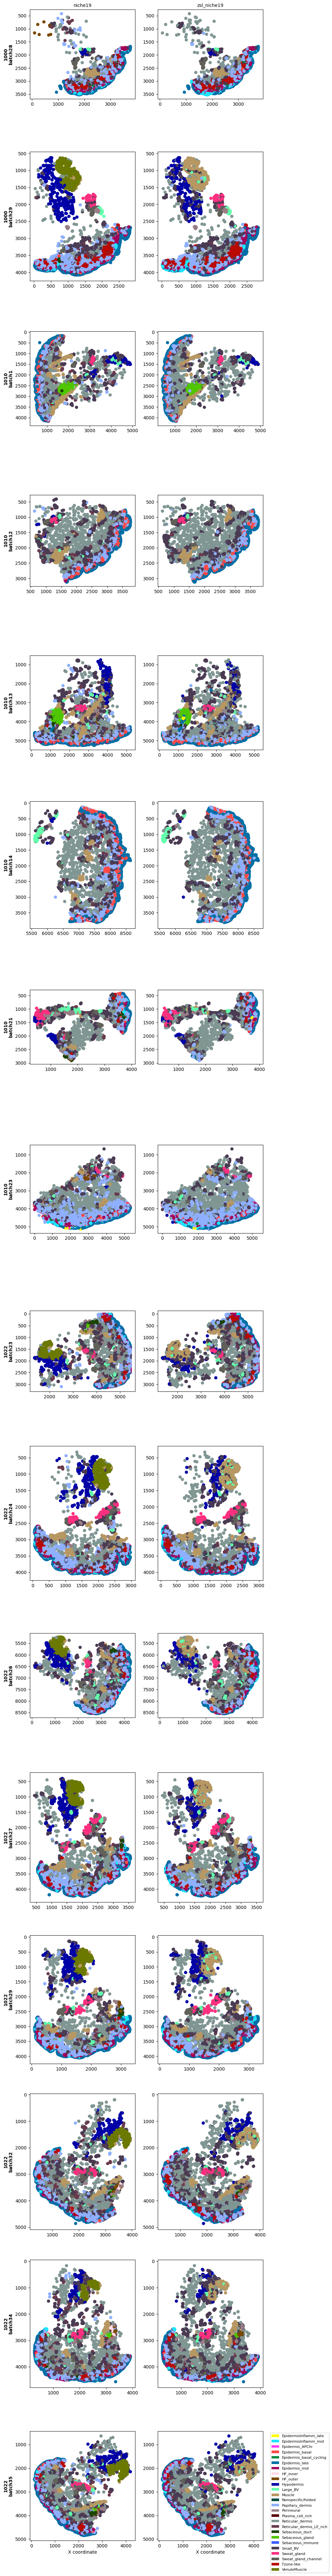

In [81]:
# Plot spatial comparison with dataset_id + batch rows
plot_fname = f"{zsl_dir}/ft-{zsl_best_ckpt['epoch']}_niche19-spatial-plots.pdf"
fig, axes = plot_spatial_comparison(
    adata=test_adata,
    column_names=['niche19', 'zsl_niche19'],
    spatial_key='spatial',
    dataset_id_col='dataset_id',
    batch_col='batch',
    spot_size=50,
    save_path=plot_fname
)

plt.show()

### Finetune + Linear

In [48]:
ftl_dir = "/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_niche-classification/artifacts/20112025_180602_255"

In [49]:
with open(f"{ftl_dir}/params.yaml", 'r') as fp:
    ftl_args = yaml.safe_load(fp)

In [24]:
ftl_ckpts = load_checkpoints_from_directory(ftl_dir)

Loaded 2 checkpoints

Epoch 0:
  Loss: 0.7348
  Accuracy: 0.8003
  Model Name: Finetune+Linear

Epoch 1:
  Loss: 0.7334
  Accuracy: 0.8010
  Model Name: Finetune+Linear


In [58]:
# Get best checkpoint from loaded checkpoints
ftl_best_ckpt = get_best_checkpoint(ftl_ckpts)

Best checkpoint: Epoch 1 with loss 0.7334


In [61]:
ftl_best_model = load_finetuned_model_for_inference(
    args=ftl_args,
    checkpoint=ftl_best_ckpt,
    device=device
)

INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
    (pos_embed): Embedding(2817, 384, padd

### Training Curves

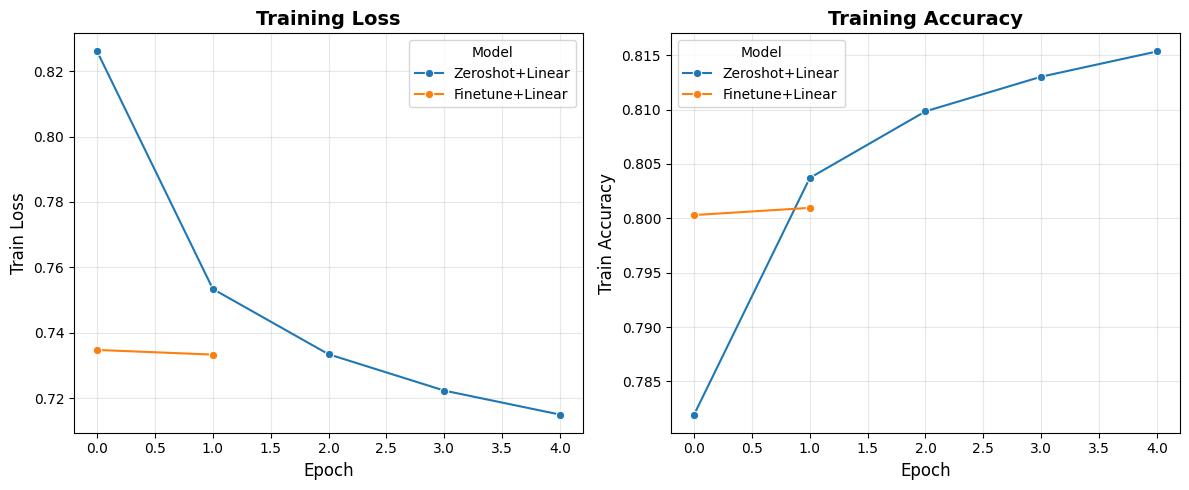

In [40]:
plot_training_curves(
    list_of_model_checkpoints=[zsl_ckpts, ftl_ckpts],
    model_names=None,
    figsize=(12, 5),
    save_path=None
)

### Inference